<a href="https://colab.research.google.com/github/Kwakjaemin1007/Like-lion_-Smart-farm/blob/main/smartfarm_strawberry_aihub_with_unzip_res_change.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from pathlib import Path

In [ ]:
str_data = "01.원천데이터"
str_label = "02.라벨링데이터"
str_common = "01.딸기_001.설향"
str_normal = "01.정상"
str_rot = "02.역병"
str_wilt = "03.시들음병"
str_burn = "04.잎끝마름"
str_yellowing = "05.황화"

base_path = Path("/content/drive/MyDrive/bootcamp_proj/proj1/AI_HUB_strawberry/01-1.정식개방데이터/Validation")
data_path = base_path / str_data / str_common
label_path = base_path / str_label / str_common
disease_categories = [str_normal, str_rot, str_wilt, str_burn, str_yellowing]

In [ ]:
from zipfile import ZipFile

In [ ]:
cat_name_to_id = {
    '잎': 0,
    '줄기': 1,
    "화방": 2,
    "과실": 3
}

In [ ]:
part_cat = {
    0: 'leaf',
    1: 'stem',
    2: "flower",
    3: "fruit",
}

In [ ]:
disease_cat = {
    0: "normal",
    1: "rot",
    2: "wilt",
    3: "burn",
    4: "yellowing"
}

In [ ]:
output_root_path = Path("/content/yolo_strawberry/")

In [ ]:
!uv pip install --system albumentations
!pip install -q albumentations

Using Python 3.12.12 environment at: /usr
Audited 1 package in 208ms


In [ ]:
from shutil import copy
from tqdm.notebook import tqdm
from tqdm.contrib import tzip
from zipfile import ZipFile, ZipInfo
import zipfile
from tempfile import TemporaryDirectory
import json
import albumentations as A
import numpy as np
import cv2

In [ ]:
train_split, test_split, valid_split = 0.8, 0.1, 0.1

# Zip the file if not exist

In [ ]:
output_root_path.mkdir(exist_ok=True)
output_train_img_path = output_root_path / "images/train"
output_train_label_path = output_root_path / "labels/train"
output_test_img_path = output_root_path / "images/test"
output_test_label_path = output_root_path / "labels/test"
output_val_img_path = output_root_path / "images/val"
output_val_label_path = output_root_path / "labels/val"
output_train_img_path.mkdir(parents=True, exist_ok=True)
output_train_label_path.mkdir(parents=True, exist_ok=True)
output_test_img_path.mkdir(parents=True, exist_ok=True)
output_test_label_path.mkdir(parents=True, exist_ok=True)
output_val_img_path.mkdir(parents=True, exist_ok=True)
output_val_label_path.mkdir(parents=True, exist_ok=True)

In [ ]:
output_img_paths = {
    "train": output_train_img_path,
    "test": output_test_img_path,
    "val": output_val_img_path,
}
output_label_paths = {
    "train": output_train_label_path,
    "test": output_test_label_path,
    "val": output_val_label_path,
}

In [ ]:
IMGSZ = 640

transform = A.Compose([
    A.LongestMaxSize(max_size=IMGSZ),
    A.PadIfNeeded(min_height=IMGSZ, min_width=IMGSZ, fill=(114, 114, 114)),
], bbox_params=A.BboxParams(format="coco", label_fields=['class_ids']))

for disease_idx, next_disease in enumerate(tqdm(disease_categories)):
    # Get zip file path
    cat_data_zip_path = base_path / str_data / f"VS_{str_common}_{next_disease}.zip"
    cat_label_zip_path = base_path / str_label / f"VL_{str_common}_{next_disease}.zip"


    with ZipFile(cat_data_zip_path) as cat_data_zip, ZipFile(cat_label_zip_path) as cat_label_zip:
        img_list = sorted(cat_data_zip.infolist(), key=lambda x: x.filename)
        label_list = sorted(cat_label_zip.infolist(), key=lambda x: x.filename)

        assert len(img_list) == len(label_list)
        data_cnt = len(img_list)

        # Using tzip to zip image an annotation - using assertion to make sure those are pair
        for data_idx, (next_img_zipinfo, next_label_zipinfo) in enumerate(tzip(img_list, label_list)):

            # Get current split
            current_progress = data_idx / data_cnt
            current_split = ""
            if current_progress <= train_split:
                current_split = "train"
            elif current_progress <= train_split + test_split:
                current_split = "test"
            else:
                current_split = "val"

            # Select output path according to current split
            output_img_path = output_img_paths[current_split]
            output_label_path = output_label_paths[current_split]

            next_img_zipinfo: ZipInfo
            next_label_zipinfo: ZipInfo
            assert Path(next_img_zipinfo.filename).stem == Path(next_label_zipinfo.filename).stem
            img_name = Path(next_img_zipinfo.filename).name
            label_name = Path(next_label_zipinfo.filename).with_suffix(".txt").name


            label_data = json.loads(cat_label_zip.read(next_label_zipinfo))
            w_img = float(label_data['images']['width'])
            h_img = float(label_data['images']['height'])

            law_bboxs = []
            law_labels = []

            # For every annotations in the json file
            for next_annot in label_data['annotations']:
                bbox = list(map(float, next_annot['bbox']))
                law_bboxs.append(bbox)

                annot_cat_id = int(next_annot['category_id'])
                part_cat_name = label_data['categories'][annot_cat_id]['name']
                part_cat_id = cat_name_to_id[part_cat_name]
                # Mix two categories (annotation category / diesease category)
                final_cat_id = disease_idx * 4 + part_cat_id
                law_labels.append(final_cat_id)

            # Resize using albumentation
            cat_data_zip.extract(next_img_zipinfo, output_img_path)
            img_bytes = cat_data_zip.read(next_img_zipinfo)
            img_np = np.frombuffer(img_bytes, dtype=np.int8)
            img = cv2.imdecode(img_np, cv2.IMREAD_COLOR)

            try:
                transformed = transform(image=img, bboxes=law_bboxs, class_ids=law_labels)
                trans_img = transformed['image']
                trans_bboxes = transformed['bboxes']
                trans_class = transformed['class_ids']
            except Exception:
                continue

            assert trans_img.shape == (640, 640, 3)

            label_file_name = output_label_path / label_name

            with open(label_file_name, "w") as f:
                if len(trans_class) != len(trans_bboxes) or len(trans_bboxes) == 0:
                    print(label_file_name)
                    continue
                for next_label, next_bbox in zip(trans_class, trans_bboxes):
                    x_min, y_min, w, h = next_bbox

                    clip = lambda x: max(0, min(1, x))
                    x = clip((x_min + w / 2) / IMGSZ)
                    y = clip((y_min + h / 2) / IMGSZ)
                    w_yolo = clip(w / IMGSZ)
                    h_yolo = clip(h / IMGSZ)

                    f.write(f"{next_label} {x} {y} {w_yolo} {h_yolo}\n")
            if label_file_name.exists():
                cv2.imwrite(str(output_img_path / img_name), trans_img)
            else:
                print(label_file_name)


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/7429 [00:00<?, ?it/s]

{'annotations': [{'area': 22982.75,
                  'bbox': [209.4, 495.72, 201.25, 114.2],
                  'category_id': 0,
                  'coordinates': [209.4,
                                  495.72,
                                  410.65,
                                  495.72,
                                  410.65,
                                  609.92,
                                  209.4,
                                  609.92],
                  'disease_status': 'N',
                  'id': 0,
                  'image_id': 32435,
                  'isCrowd': 0},
                 {'area': 26552.06,
                  'bbox': [326.16, 582.36, 169.24, 156.89],
                  'category_id': 1,
                  'coordinates': [326.16,
                                  582.36,
                                  495.4,
                                  582.36,
                                  495.4,
                                  739.25,
               

  0%|          | 0/3390 [00:00<?, ?it/s]

{'annotations': [{'area': 92364.99,
                  'bbox': [328.7, 112.77, 344.89, 267.81],
                  'category_id': 0,
                  'coordinates': [328.7,
                                  112.77,
                                  673.58,
                                  112.77,
                                  673.58,
                                  380.58,
                                  328.7,
                                  380.58],
                  'disease_status': 'N',
                  'id': 0,
                  'image_id': 91,
                  'isCrowd': 0},
                 {'area': 10203.78,
                  'bbox': [324.79, 609.71, 100.52, 101.51],
                  'category_id': 1,
                  'coordinates': [324.79,
                                  609.71,
                                  425.31,
                                  609.71,
                                  425.31,
                                  711.22,
               

  0%|          | 0/4753 [00:00<?, ?it/s]

{'annotations': [{'area': 75140.14,
                  'bbox': [532.33, 272.45, 360.54, 208.41],
                  'category_id': 0,
                  'coordinates': [532.33,
                                  272.45,
                                  892.87,
                                  272.45,
                                  892.87,
                                  480.86,
                                  532.33,
                                  480.86],
                  'disease_status': 'N',
                  'id': 0,
                  'image_id': 164,
                  'isCrowd': 0},
                 {'area': 1423.59,
                  'bbox': [227.08, 273.8, 23.55, 60.45],
                  'category_id': 1,
                  'coordinates': [227.08,
                                  273.8,
                                  250.63,
                                  273.8,
                                  250.63,
                                  334.25,
                 

  0%|          | 0/1989 [00:00<?, ?it/s]

{'annotations': [{'area': 62654.17,
                  'bbox': [360.06, 162.49, 279.22, 224.39],
                  'category_id': 0,
                  'coordinates': [360.06,
                                  162.49,
                                  639.28,
                                  162.49,
                                  639.28,
                                  386.88,
                                  360.06,
                                  386.88],
                  'disease_status': 'N',
                  'id': 0,
                  'image_id': 46344,
                  'isCrowd': 0},
                 {'area': 53498.82,
                  'bbox': [181.95, 285.11, 360.31, 148.48],
                  'category_id': 1,
                  'coordinates': [181.95,
                                  285.11,
                                  542.26,
                                  285.11,
                                  542.26,
                                  433.59,
         

  0%|          | 0/1551 [00:00<?, ?it/s]

{'annotations': [{'area': 45659.14,
                  'bbox': [441.76, 227.39, 249.34, 183.12],
                  'category_id': 0,
                  'coordinates': [441.76,
                                  227.39,
                                  691.1,
                                  227.39,
                                  691.1,
                                  410.51,
                                  441.76,
                                  410.51],
                  'disease_status': 'N',
                  'id': 0,
                  'image_id': 37996,
                  'isCrowd': 0},
                 {'area': 68978.51,
                  'bbox': [689.43, 175.04, 298.88, 230.79],
                  'category_id': 1,
                  'coordinates': [689.43,
                                  175.04,
                                  988.31,
                                  175.04,
                                  988.31,
                                  405.83,
           

## Zip it

In [ ]:
import shutil
shutil.make_archive("strawberry_data_640x640", "zip", output_root_path)

'/content/strawberry_data-640x640.zip'

In [ ]:
!cp /content/strawberry_data_640x640.zip /content/drive/MyDrive/bootcamp_proj/proj1/strawberry_data_640x640.zip

# Else

In [ ]:
data_zip_path = Path("/content/drive/MyDrive/bootcamp_proj/proj1/strawberry_data_640x640.zip")

In [ ]:
!cp {data_zip_path} /content/

In [ ]:
!unzip -q "./strawberry_data_640x640.zip" -d /content/yolo_strawberry

# Training

In [ ]:
!uv pip install --system ultralytics
!pip install -q ultralytics

Using Python 3.12.12 environment at: /usr
Resolved 50 packages in 400ms
Prepared 2 packages in 111ms
Installed 2 packages in 21ms
 + ultralytics==8.3.252
 + ultralytics-thop==2.0.18


In [ ]:
import wandb
wandb.login()

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Find your API key here: https://wandb.ai/authorize
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: dhnam0502 (dhnam0502-likelion) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [ ]:
import ultralytics

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
ultralytics.checks()

Ultralytics 8.3.252 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 46.1/235.7 GB disk)


In [ ]:
category: dict[int, str] = {}
for disease_idx, disease_name in disease_cat.items():
    for part_idx, part_name in part_cat.items():
        category[disease_idx * 4 + part_idx] = f"{disease_name}_{part_name}"

In [ ]:
category

{0: 'normal_leaf',
 1: 'normal_stem',
 2: 'normal_flower',
 3: 'normal_fruit',
 4: 'rot_leaf',
 5: 'rot_stem',
 6: 'rot_flower',
 7: 'rot_fruit',
 8: 'wilt_leaf',
 9: 'wilt_stem',
 10: 'wilt_flower',
 11: 'wilt_fruit',
 12: 'burn_leaf',
 13: 'burn_stem',
 14: 'burn_flower',
 15: 'burn_fruit',
 16: 'yellowing_leaf',
 17: 'yellowing_stem',
 18: 'yellowing_flower',
 19: 'yellowing_fruit'}

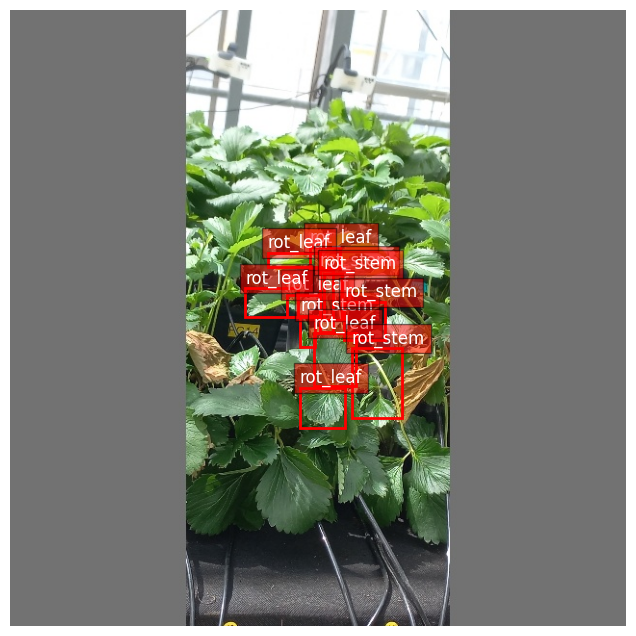

In [ ]:
import cv2
import matplotlib.pyplot as plt

def visualize_yolo(image_path, label_path, classes):
    # 이미지 읽기 (OpenCV는 BGR이므로 RGB로 변환)
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape

    # 라벨 파일 읽기
    with open(label_path, 'r') as f:
        lines = f.readlines()

    plt.figure(figsize=(12, 8))
    plt.imshow(img)
    ax = plt.gca()

    for line in lines:
        parts = list(map(float, line.strip().split()))
        class_id = int(parts[0])
        x_center, y_center, width, height = parts[1:]

        # YOLO 좌표 역변환 (Normalized xywh -> pixel xy_min)
        x_min = (x_center - width / 2) * w
        y_min = (y_center - height / 2) * h
        box_w = width * w
        box_h = height * h

        # 사각형 그리기 (Matplotlib patch)
        rect = plt.Rectangle((x_min, y_min), box_w, box_h,
                             fill=False, color='red', linewidth=2)
        ax.add_patch(rect)

        # 텍스트 넣기
        label_text = category[class_id] if classes else str(class_id)
        ax.text(x_min, y_min - 5, label_text,
                bbox=dict(facecolor='red', alpha=0.5), color='white', fontsize=12)

    plt.axis('off')
    plt.show()

# 사용
categories = ['strawberry_class_0', 'strawberry_class_1'] # 본인의 클래스 리스트
visualize_yolo(
    "/content/yolo_strawberry/images/test/딸기_설향_역병_93_013_220908130549.jpg",
    "/content/yolo_strawberry/labels/test/딸기_설향_역병_93_013_220908130549.txt",
    categories
)

In [ ]:
from ultralytics import YOLO

In [ ]:
import yaml

data = {}
data['train'] = str(output_root_path / "images" / "train")
data['val'] = str(output_root_path / "images" / "val")
data['test'] = str(output_root_path / "images" / "test")
data['nc'] = 20
data['names'] = list(category.values())
with open(output_root_path / "data.yaml", "w") as f:
    yaml.dump(data, f, default_flow_style=False)

In [ ]:
!cat {output_root_path / "data.yaml"}

names:
- normal_leaf
- normal_stem
- normal_flower
- normal_fruit
- rot_leaf
- rot_stem
- rot_flower
- rot_fruit
- wilt_leaf
- wilt_stem
- wilt_flower
- wilt_fruit
- burn_leaf
- burn_stem
- burn_flower
- burn_fruit
- yellowing_leaf
- yellowing_stem
- yellowing_flower
- yellowing_fruit
nc: 20
test: /content/yolo_strawberry/images/test
train: /content/yolo_strawberry/images/train
val: /content/yolo_strawberry/images/val


In [ ]:
model = YOLO("yolo11n.pt")

In [ ]:
wandb.finish()

In [ ]:
ultralytics.settings.update({"wandb": True})

In [ ]:
ultralytics.settings

{'settings_version': '0.0.6',
 'datasets_dir': '/content/datasets',
 'weights_dir': 'weights',
 'runs_dir': 'runs',
 'uuid': '569f3ba64b326db489132663f79cd37279811de477381b83ac131e6cdd129cbb',
 'sync': True,
 'api_key': '',
 'openai_api_key': '',
 'clearml': True,
 'comet': True,
 'dvc': True,
 'hub': True,
 'mlflow': True,
 'neptune': True,
 'raytune': True,
 'tensorboard': False,
 'wandb': True,
 'vscode_msg': True,
 'openvino_msg': True}

In [ ]:
results = model.train(
    data=output_root_path / "data.yaml",
    epochs=100,
    imgsz=640,
    project="smartfarm-strawberry",
    name="baseline-yolo11n",
    batch=-1,
    patience=10,
    mosaic=0.0,
)

Ultralytics 8.3.252 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_strawberry/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.0, multi_scale=False, name=baseline-yolo11n, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=10, perspective=0.0, p

Overriding model.yaml nc=80 with nc=20

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      6640  ultralytics.nn.modules.block.C3k2            [32, 64, 1, False, 0.25]      
  3                  -1  1     36992  ultralytics.nn.modules.conv.Conv             [64, 64, 3, 2]                
  4                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  5                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  6                  -1  1     87040  ultralytics.nn.modules.block.C3k2            [128, 128, 1, True]           
  7                  -1  1    295424  ultralytic

In [ ]:
import gc
gc.collect()
import torch
torch.cuda.empty_cache()

In [ ]:
save_path = Path(results.save_dir) / "best_pt"
print(save_path)
!cp {save_path} /content/drive/MyDrive/bootcamp_proj/proj1/baseline_best.pt

/bin/bash: -c: line 1: syntax error near unexpected token `('
/bin/bash: -c: line 1: `cp {Path(model.save_dir) / "best.pt"} /content/drive/MyDrive/bootcamp_proj/proj1/baseline_best.pt'
